In [34]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier

from src.preprocessing import make_pipeline as project_make_pipeline
from src.evaluation import run_cv
from src.config import RANDOM_SEED

In [35]:
from sklearn.ensemble import RandomForestClassifier

In [36]:
import pandas as pd
from src.config import TARGET_COL

dev = pd.read_csv("../data/dev.csv")

y = dev[TARGET_COL]
X = dev.drop(columns=[TARGET_COL])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (120000, 10)
y shape: (120000,)


In [37]:
rf_pipe = project_make_pipeline(
    RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
)

In [38]:
scores, summary = run_cv(rf_pipe, X, y)

print(summary)

{'roc_auc_mean': np.float64(0.858214070773373), 'roc_auc_std': np.float64(0.0023349295790612143), 'pr_auc_mean': np.float64(0.38632297536025945), 'pr_auc_std': np.float64(0.0037380198892657483), 'brier_mean': np.float64(0.09588286201683398), 'brier_std': np.float64(0.0010922683149228066)}


In [39]:
for metric, value in summary.items():
    print(f"{metric}: {value:.6f}")

roc_auc_mean: 0.858214
roc_auc_std: 0.002335
pr_auc_mean: 0.386323
pr_auc_std: 0.003738
brier_mean: 0.095883
brier_std: 0.001092


### Step 7.2 — Random Forest Results and Interpretation

Random Forest was evaluated using stratified cross-validation with the same preprocessing pipeline used for the baseline models.

**Results:**

* ROC-AUC: 0.858214 ± 0.002335
* PR-AUC: 0.386323 ± 0.003738
* Brier Score: 0.095883 ± 0.001092

**Comparison with baseline models:**

1. Random Forest achieved better ROC-AUC and PR-AUC than Logistic Regression.
2. Random Forest also achieved a lower Brier Score than Logistic Regression.
3. Its standard deviations are relatively small, indicating consistent performance across folds.
4. Dummy Classifier provides a reference baseline and performs substantially worse in ROC-AUC and PR-AUC.

**Conclusion:**

Random Forest improves upon Logistic Regression across all three evaluation metrics. It is a promising stronger model for the RiskLens project.


In [40]:
from xgboost import XGBClassifier

In [41]:
spw = (y == 0).sum() / (y == 1).sum()

print("Scale positive weight:", spw)

Scale positive weight: 13.960728088766986


In [42]:
xgb_pipe = project_make_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=spw,
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
)

In [43]:
xgb_scores, xgb_summary = run_cv(xgb_pipe, X, y)

print(xgb_summary)

{'roc_auc_mean': np.float64(0.8643979304130986), 'roc_auc_std': np.float64(0.0033468468399708417), 'pr_auc_mean': np.float64(0.3996597250108554), 'pr_auc_std': np.float64(0.0058422436008070885), 'brier_mean': np.float64(0.1397908389568329), 'brier_std': np.float64(0.0008414242050193045)}


In [44]:
for metric, value in xgb_summary.items():
    print(f"{metric}: {value:.6f}")

roc_auc_mean: 0.864398
roc_auc_std: 0.003347
pr_auc_mean: 0.399660
pr_auc_std: 0.005842
brier_mean: 0.139791
brier_std: 0.000841


### Step 7.3 — XGBoost Results and Interpretation

XGBoost was evaluated using stratified cross-validation with the same preprocessing pipeline used for the previous models.

**Results:**

* ROC-AUC: 0.864398 ± 0.003347
* PR-AUC: 0.399660 ± 0.005842
* Brier Score: 0.139791 ± 0.000841

**Comparison with previous models:**

1. XGBoost achieved the highest ROC-AUC and PR-AUC among the four models.
2. Its Brier Score is better than Logistic Regression but worse than Random Forest.
3. Its standard deviations are relatively low, indicating consistent performance across folds.

**Conclusion:**

XGBoost currently provides the strongest ranking performance based on ROC-AUC and PR-AUC. However, Random Forest has better probability prediction quality based on the Brier Score.


In [45]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src folder exists:", (PROJECT_ROOT / "src").exists())

Project root: c:\Users\HP\RiskLens
src folder exists: True


In [46]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer

from src.preprocessing import clean_data, PercentileCapper

In [47]:
lr_none = project_make_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_SEED
    ),
    scale=True
)

none_scores, none_summary = run_cv(lr_none, X, y)

print("No Class Weight Results:")
for metric, value in none_summary.items():
    print(f"{metric}: {value:.6f}")

No Class Weight Results:
roc_auc_mean: 0.849859
roc_auc_std: 0.004232
pr_auc_mean: 0.377702
pr_auc_std: 0.006131
brier_mean: 0.050753
brier_std: 0.000322


In [48]:
lr_balanced = project_make_pipeline(
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ),
    scale=True
)

balanced_scores, balanced_summary = run_cv(
    lr_balanced, X, y
)

print("Balanced Class Weight Results:")
for metric, value in balanced_summary.items():
    print(f"{metric}: {value:.6f}")

Balanced Class Weight Results:
roc_auc_mean: 0.854959
roc_auc_std: 0.004294
pr_auc_mean: 0.382761
pr_auc_std: 0.006798
brier_mean: 0.145141
brier_std: 0.000625


In [49]:
smote_pipe = ImbPipeline(steps=[
    (
        "cleaner",
        FunctionTransformer(clean_data, validate=False)
    ),

    (
        "capper",
        PercentileCapper(
            columns=[
                "RevolvingUtilizationOfUnsecuredLines",
                "DebtRatio"
            ],
            percentile=0.99
        )
    ),

    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=False
        )
    ),

    ("scaler", StandardScaler()),

    (
        "smote",
        SMOTE(random_state=RANDOM_SEED)
    ),

    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_SEED
        )
    )
])

smote_scores, smote_summary = run_cv(smote_pipe, X, y)

print("SMOTE Results:")
for metric, value in smote_summary.items():
    print(f"{metric}: {value:.6f}")

SMOTE Results:
roc_auc_mean: 0.854104
roc_auc_std: 0.003985
pr_auc_mean: 0.382406
pr_auc_std: 0.006610
brier_mean: 0.145450
brier_std: 0.000643


In [50]:
comparison = pd.DataFrame([
    {"Strategy": "No Class Weight", **none_summary},
    {"Strategy": "Balanced Class Weight", **balanced_summary},
    {"Strategy": "SMOTE", **smote_summary}
])

comparison

,Strategy,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_mean,brier_std
0,No Class Weight,0.849859,0.004232,0.377702,0.006131,0.050753,0.000322
1,Balanced Class Weight,0.854959,0.004294,0.382761,0.006798,0.145141,0.000625
2,SMOTE,0.854104,0.003985,0.382406,0.006610,0.145450,0.000643


### Step 7.4 — Comparison of Class-Imbalance Strategies

Three imbalance strategies were evaluated using Logistic Regression and stratified cross-validation.

**Results:**

| Strategy              |  ROC-AUC |   PR-AUC | Brier Score |
| --------------------- | -------: | -------: | ----------: |
| No Class Weight       | 0.849859 | 0.377702 |    0.050753 |
| Balanced Class Weight | 0.854959 | 0.382761 |    0.145141 |
| SMOTE                 | 0.854104 | 0.382406 |    0.145450 |

**Observations:**

1. Balanced class weighting achieved the highest ROC-AUC and PR-AUC.
2. No class weighting achieved the lowest Brier Score.
3. SMOTE performed slightly below balanced class weighting in ROC-AUC and PR-AUC.
4. Balanced class weighting appears to be the strongest strategy for identifying the minority default class based on PR-AUC.

**Conclusion:**

Balanced class weighting is the current preferred strategy for Logistic Regression based on PR-AUC. However, probability calibration must also be considered before selecting the final model.


In [51]:
%pip install xgboost scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

In [53]:
param_distributions = {
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__min_child_weight": [1, 3, 5, 7],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.8, 0.9, 1.0]
}

In [54]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

random_search = RandomizedSearchCV(
    estimator=xgb_pipe,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [55]:
random_search.fit(X, y)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.8, 0.9, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [3, 4, ...], 'model__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum sco

In [56]:
print("Best PR-AUC:", random_search.best_score_)
print("\nBest Parameters:")
print(random_search.best_params_)

Best PR-AUC: 0.4009788679392422

Best Parameters:
{'model__subsample': 0.8, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


In [57]:
tuning_results = pd.DataFrame(random_search.cv_results_)

tuning_results[
    ["rank_test_score", "mean_test_score", "std_test_score", "params"]
].sort_values("rank_test_score").head()

,rank_test_score,mean_test_score,std_test_score,params
3,1,0.400979,0.006476,"{'model__subsample': 0.8, 'model__min_child_we..."
8,2,0.400838,0.005469,"{'model__subsample': 0.9, 'model__min_child_we..."
1,3,0.400327,0.005888,"{'model__subsample': 0.9, 'model__min_child_we..."
6,4,0.400095,0.004780,"{'model__subsample': 0.9, 'model__min_child_we..."
11,5,0.399742,0.006449,"{'model__subsample': 0.8, 'model__min_child_we..."


In [58]:
print("Best XGBoost Parameters:")

for param, value in random_search.best_params_.items():
    print(f"{param}: {value}")

Best XGBoost Parameters:
model__subsample: 0.8
model__min_child_weight: 5
model__max_depth: 4
model__learning_rate: 0.05
model__colsample_bytree: 1.0


In [59]:
tuned_xgb = random_search.best_estimator_

tuned_scores, tuned_summary = run_cv(tuned_xgb, X, y)

print("Tuned XGBoost Results:")

for metric, value in tuned_summary.items():
    print(f"{metric}: {value:.6f}")

Tuned XGBoost Results:
roc_auc_mean: 0.864819
roc_auc_std: 0.003349
pr_auc_mean: 0.400979
pr_auc_std: 0.006476
brier_mean: 0.139564
brier_std: 0.000909


### Step 7.5 — XGBoost Hyperparameter Tuning

RandomizedSearchCV was used to tune XGBoost using 20 parameter combinations and 5-fold StratifiedKFold cross-validation on the development dataset.

**Best hyperparameters:**

* max_depth: 4
* learning_rate: 0.05
* min_child_weight: 5
* subsample: 0.8
* colsample_bytree: 1.0

**Tuned model results:**

* ROC-AUC: 0.864819 ± 0.003349
* PR-AUC: 0.400979 ± 0.006476
* Brier Score: 0.139564 ± 0.000909

**Comparison with untuned XGBoost:**

The tuned model achieved small improvements in ROC-AUC, PR-AUC and Brier Score.

**Conclusion:**

Hyperparameter tuning produced a modest improvement in XGBoost performance. The tuned configuration will be considered for subsequent model evaluation.



| Model                           |      ROC-AUC |       PR-AUC |  Brier Score |
| ------------------------------- | -----------: | -----------: | -----------: |
| Dummy Classifier                |     0.500000 |     0.066842 |     0.062374 |
| Logistic Regression             |     0.854959 |     0.382761 |     0.145141 |
| Random Forest                   |     0.858214 |     0.386323 | **0.095883** |
| XGBoost                         |     0.864398 |     0.399660 |     0.139791 |
| XGBoost — Tuned                 | **0.864819** | **0.400979** |     0.139564 |
| Logistic Regression — No Weight |     0.849859 |     0.377702 |     0.050753 |
| Logistic Regression — Balanced  |     0.854959 |     0.382761 |     0.145141 |
| Logistic Regression — SMOTE     |     0.854104 |     0.382406 |     0.145450 |


### Step 7.7 — Model Development Checkpoint

* [x] Random Forest completed.
* [x] XGBoost baseline completed.
* [x] Imbalance strategy comparison completed.
* [x] XGBoost hyperparameter tuning completed.
* [x] Results table updated.

**Preliminary observations:**

Tuned XGBoost achieved the highest development cross-validation PR-AUC of 0.400979.

Random Forest achieved the lowest Brier Score among the main baseline models, at 0.095883.

**Model selection:**

Tuned XGBoost is the preliminary leading candidate based on PR-AUC. However, final model selection requires examining calibration quality as well. The model will not be considered the final winner until this comparison is completed.

The locked test set remains untouched.


In [60]:
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

In [61]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

rf_prob = cross_val_predict(
    rf_pipe, X, y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

xgb_prob = cross_val_predict(
    tuned_xgb, X, y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [62]:
print("Random Forest Brier Score:",
      brier_score_loss(y, rf_prob))

print("Tuned XGBoost Brier Score:",
      brier_score_loss(y, xgb_prob))

Random Forest Brier Score: 0.09588286201683398
Tuned XGBoost Brier Score: 0.13956372439861298


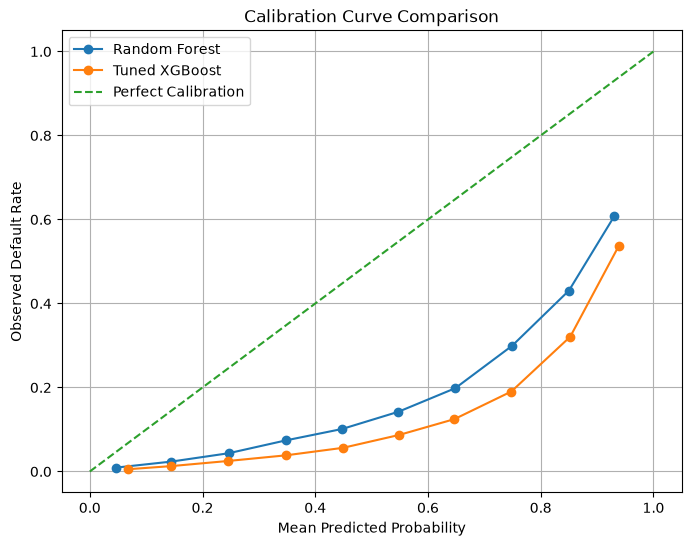

In [63]:
rf_true, rf_pred = calibration_curve(
    y, rf_prob, n_bins=10, strategy="uniform"
)

xgb_true, xgb_pred = calibration_curve(
    y, xgb_prob, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(rf_pred, rf_true, marker="o",
         label="Random Forest")

plt.plot(xgb_pred, xgb_true, marker="o",
         label="Tuned XGBoost")

plt.plot([0, 1], [0, 1], linestyle="--",
         label="Perfect Calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Calibration Comparison — Random Forest vs Tuned XGBoost

Out-of-fold predictions were generated using 5-fold StratifiedKFold cross-validation. Calibration curves were plotted using 10 uniform bins.

**Brier Scores:**

* Random Forest: 0.095883
* Tuned XGBoost: 0.139564

**Observations:**

1. Random Forest achieved a lower Brier Score than tuned XGBoost.
2. The Random Forest calibration curve is generally closer to the perfect-calibration diagonal.
3. Both models show some overestimation of default probabilities.
4. Tuned XGBoost achieved higher ROC-AUC and PR-AUC, indicating stronger ranking performance.

**Model selection decision:**

Random Forest is the current preferred candidate when probability reliability is important. Tuned XGBoost remains a strong alternative when ranking performance is prioritized.

Final selection will be confirmed through evaluation on the locked test set, which remains untouched.


### Final Development Model Selection

Based on development cross-validation results:

1).Tuned XGBoost is the preferred candidate for ranking high-risk customers because it achieved the highest PR-AUC of 0.400979.

2).Random Forest is a strong alternative for probability reliability because it achieved a lower Brier Score of 0.095883 and showed better calibration.

3).Both models will be retained for final evaluation. The locked test set remains untouched.


**Decision:**

Tuned XGBoost is the preferred candidate when identifying and ranking high-risk customers is the primary objective.

Random Forest is a strong alternative when probability reliability is prioritized.

Both models will be retained as candidates for final evaluation. The locked test set has not been used.
